In [5]:
from langgraph.graph import StateGraph,START,END
from typing import TypedDict

In [3]:
class BatsmanState(TypedDict):
    runs: int
    balls:int
    four: int
    six: int

    sr: float
    bpb: float
    boundary_percentage: float
    summary: str

In [16]:
# functions to calculate sr, bpb and boundary percentage 
def calculate_sr(state:BatsmanState):
    sr=(state['runs']/state['balls'])*100
    
    return {'sr':sr}

def calculate_bpb(state:BatsmanState):
    bpb=state['balls']/(state['four']+state['six'])
    
    return {'bpb':bpb}

def calculate_boundary_percentage(state:BatsmanState):
    total_boundaries = state['four']*4 + state['six']*6
    boundary_percentage = (total_boundaries / state['balls']) * 100
    return {'boundary_percentage': boundary_percentage}

def summery(state:BatsmanState):
    summery = f"Runs: {state['runs']}, Balls: {state['balls']}, Fours: {state['four']}, Sixes: {state['six']}, SR: {state['sr']:.2f}, BPB: {state['bpb']:.2f}, Boundary Percentage: {state['boundary_percentage']:.2f}%"
    return {'summery': summery}

In [18]:
# define graph 
graph=StateGraph(BatsmanState)

# add nodes 
graph.add_node('calculate_sr',calculate_sr)
graph.add_node('calculate_bpb',calculate_bpb)
graph.add_node('calculate_boundary_percentage',calculate_boundary_percentage)
graph.add_node('summery',summery)

# add edges
graph.add_edge(START,'calculate_sr')
graph.add_edge(START,'calculate_bpb')
graph.add_edge(START,'calculate_boundary_percentage')

graph.add_edge('calculate_sr','summery')
graph.add_edge('calculate_bpb','summery')
graph.add_edge('calculate_boundary_percentage','summery')

graph.add_edge('summery',END)


In [19]:
# compile the graph
workflow=graph.compile()

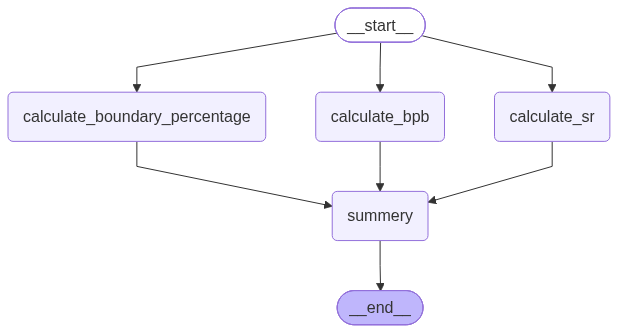

In [20]:
graph.compile()

In [21]:
# run the graph
initial_state={"runs": 50, "balls": 100, "four": 5, "six": 2}
final_state=workflow.invoke(initial_state)
print(final_state)

{'runs': 50, 'balls': 100, 'four': 5, 'six': 2, 'sr': 50.0, 'bpb': 14.285714285714286, 'boundary_percentage': 32.0}
